## Celda 1. SP-004 — DJD-1/3

### Qué hace esta celda

Presenta el objetivo del Spike y el candidato M4 que se investigará.

### Por qué la necesitamos

El notebook debe dejar claro desde la primera celda que DJD es experimental.

### Qué deberíamos observar

FF, BF y WF se conservan como baselines; no se integra DJD en producción.

## Celda 2. Filler descartado como candidato principal

### Qué hace esta celda

Resume por qué FL queda como evidencia histórica y no como candidato principal.

### Por qué la necesitamos

La auditoría observó que FF de NewGlass ya ordena por área y ambos coincidieron en los fixtures.

### Qué deberíamos observar

En SMALL, MEDIUM y COMPLEX, Filler y FF coincidieron en cobertura, número de fuentes y aprovechamiento. La búsqueda Filler sí tuvo trazas y costo propios, pero no mostró una dimensión de selección suficiente para ser el candidato principal de M4. Se conservan su informe, notebook y resultados bajo nombres de candidato descartado.

## Celda 3. Qué es Djang and Finch

### Qué hace esta celda

Resume el DJD 1D y la adaptación académica a irregular 2D.

### Por qué la necesitamos

Separar ambos dominios evita aplicar capacidad lineal como si fuera geometría.

### Qué deberíamos observar

En 2D, DJD selecciona grupos y otra rutina debe validar el placement.

## Celda 4. Diferencia frente a FF/BF/WF

### Qué hace esta celda

Explica que los baselines puntúan una pieza actual y DJD puede proponer 1, 2 o 3 unidades juntas.

### Por qué la necesitamos

La diferencia de política debe analizarse en decisiones y no solo en métricas finales.

### Qué deberíamos observar

Una secuencia de dos piezas elegida como grupo distinguiría decisiones aunque placements finales coincidieran.

## Celda 5. Definición DJD-1/3 y tolerancia

### Qué hace esta celda

Describe el umbral inicial y `w` basado en la publicación.

### Por qué la necesitamos

El incremento de desperdicio no debe ser un número arbitrario.

### Qué deberíamos observar

La fuente académica recomienda empíricamente un incremento de 1/20 del área nominal total del objeto; NewGlass usa el mismo denominador y valida cabida con el raster.

## Celda 6. Preparación del entorno

### Qué hace esta celda

Configura imports del repo, métodos y casos.

### Por qué la necesitamos

El loader TA-027 necesita los paquetes de backend y los JSON versionados.

### Qué deberíamos observar

Se muestra la raíz y se confirma ejecución secuencial.

In [1]:
from pathlib import Path  # Importamos Path para resolver rutas tanto en local como en Colab.
import sys  # Importamos sys para agregar el backend al path de imports.
import json  # Importamos JSON para leer la instancia discriminante.
from decimal import Decimal  # Usamos Decimal en límites y áreas de configuración.
repo_root = Path.cwd()  # Tomamos el directorio actual como raíz candidata.
if not (repo_root / "experiments/optimization/loader.py").exists():  # Comprobamos que la carpeta actual contenga los fixtures.
    repo_root = Path("/content/NewGlass")  # Usamos la ubicación sugerida para clonar el repositorio en Colab.
if not (repo_root / "experiments/optimization/loader.py").exists():  # Detenemos con instrucción legible si falta el repo.
    raise RuntimeError("Clona NewGlass en /content/NewGlass o ejecuta desde la raíz del repositorio.")  # Explicamos cómo preparar Colab.
sys.path.insert(0, str(repo_root / "backend"))  # Habilitamos los imports app del motor actual.
sys.path.insert(0, str(repo_root))  # Habilitamos imports del loader y del experimento.
from experiments.optimization.loader import CASES, load_problem, read_case  # Reutilizamos la lista y loader TA-027.
from experiments.optimization.djd import DJDExperimental  # Importamos la política aislada DJD.
from experiments.optimization.djd.run_benchmark import DISCRIMINANT, METHODS, load_experimental_case, run_one  # Reutilizamos el ejecutor secuencial.
print("Repositorio:", repo_root)  # Confirmamos la raíz que usa el notebook.
print("Métodos:", [name for name, _ in METHODS], "| multiprocessing: no")  # Confirmamos métodos y modo de recursos.

Repositorio: C:\Users\patri\GitHub\optimizador-vidrio
Métodos: ['FF', 'BF', 'WF', 'DJD-1/3'] | multiprocessing: no


### Interpretación de la salida

El notebook usa una copia del repositorio y no necesita acceso a base de datos; métodos ejecutan uno por uno.

## Celda 7. Validación de fixtures

### Qué hace esta celda

Lee SMALL, MEDIUM, COMPLEX y el caso didáctico separado.

### Por qué la necesitamos

La instancia adicional no debe confundirse con TA-027.

### Qué deberíamos observar

Los conteos se obtienen de los JSON sin modificarlos.

In [2]:
fixture_data = {}  # Creamos un resumen de entradas para las celdas siguientes.
for case_id in CASES:  # Recorremos los tres fixtures oficiales en su orden estable.
    data = read_case(case_id)  # Leemos una copia del JSON oficial.
    fixture_data[case_id] = data  # Guardamos datos sin escribirlos al archivo.
    print(case_id, "filas de piezas:", len(data["pieces"]), "fuentes:", len(data["stock"]), "config:", data["config"])  # Mostramos los parámetros originales.
discriminant_path = repo_root / "experiments/optimization/djd/cases/DJD-DISCRIMINANT-001.json"  # Localizamos el caso no oficial.
discriminant_data = json.loads(discriminant_path.read_text(encoding="utf-8"))  # Leemos su etiqueta y configuración.
print(discriminant_data["label"], "filas:", len(discriminant_data["pieces"]))  # Separamos explícitamente el caso didáctico.

EXP-SMALL-001 filas de piezas: 1 fuentes: 2 config: {'resolution_mm': 1, 'angular_step_deg': 5, 'margin_mm': 0, 'separation_mm': 0}
EXP-MEDIUM-001 filas de piezas: 3 fuentes: 3 config: {'resolution_mm': 1, 'angular_step_deg': 5, 'margin_mm': 1, 'separation_mm': 1}
EXP-COMPLEX-001 filas de piezas: 6 fuentes: 5 config: {'resolution_mm': 1, 'angular_step_deg': 5, 'margin_mm': 1, 'separation_mm': 1}
CASO DE DISCRIMINACIÓN HEURÍSTICA — NO FORMA PARTE DE TA-027 filas: 3


### Interpretación de la salida

Los tres fixtures oficiales continúan intactos; el JSON discriminante está en el directorio de DJD.

## Celda 8. EXP-SMALL-001

### Qué hace esta celda

Explica el tamaño del caso SMALL y carga sus snapshots.

### Por qué la necesitamos

Un caso homogéneo comprueba el recorrido básico con poco costo.

### Qué deberíamos observar

Se muestran unidades expandidas y grupo material-espesor.

In [3]:
small_data, small_problem = load_experimental_case("EXP-SMALL-001")  # Reutilizamos la entrada oficial y la construcción de snapshots.
print("unidades expandidas:", len(small_problem.units))  # Contamos las unidades físicas solicitadas.
print("grupos material-espesor:", len(small_problem.groups))  # Confirmamos separación por compatibilidad.

unidades expandidas: 3
grupos material-espesor: 1


### Interpretación de la salida

SMALL tiene tres unidades de una geometría y fuentes retazo/plancha del mismo material.

## Celda 9. EXP-MEDIUM-001

### Qué hace esta celda

Explica la heterogeneidad del caso MEDIUM.

### Por qué la necesitamos

Las combinaciones pequeñas pueden elegir unidades de tamaños diferentes.

### Qué deberíamos observar

Se informa cantidad expandida y stock compatible.

In [4]:
medium_data, medium_problem = load_experimental_case("EXP-MEDIUM-001")  # Creamos snapshots nuevos de MEDIUM.
print("unidades expandidas:", len(medium_problem.units))  # Contamos piezas individuales después de expandir cantidades.
print("fuentes físicas:", sum(len(group.stock_candidates) for group in medium_problem.groups))  # Contamos fuentes compatibles.

unidades expandidas: 9
fuentes físicas: 4


### Interpretación de la salida

MEDIUM contiene nueve unidades; el loader mantiene material y espesor como clave de agrupación.

## Celda 10. EXP-COMPLEX-001

### Qué hace esta celda

Carga COMPLEX y resume su número de grupos y fuentes.

### Por qué la necesitamos

Este caso prueba DJD con varios grupos independientes.

### Qué deberíamos observar

Se evita combinar unidades incompatibles a través de grupos.

In [5]:
complex_data, complex_problem = load_experimental_case("EXP-COMPLEX-001")  # Reconstruimos COMPLEX con el loader congelado.
print("unidades expandidas:", len(complex_problem.units))  # Informamos la carga del pedido.
print("grupos material-espesor:", len(complex_problem.groups))  # Contamos grupos compatibles.
print("fuentes físicas:", sum(len(group.stock_candidates) for group in complex_problem.groups))  # Informamos unidades de inventario.

unidades expandidas: 24
grupos material-espesor: 2
fuentes físicas: 7


### Interpretación de la salida

COMPLEX tiene 24 unidades y cinco grupos de compatibilidad; DJD reinicia su fuente activa dentro de cada grupo.

## Celda 11. Orden de piezas

### Qué hace esta celda

Muestra el orden del JSON y el orden estable por área que usará DJD.

### Por qué la necesitamos

Las permutaciones dentro de cada grupo parten de un orden reproducible.

### Qué deberíamos observar

El desempate se basa en ID e índice de unidad.

In [6]:
before = [(row["id_pieza"], row["cantidad"]) for row in medium_data["pieces"]]  # Registramos el orden de filas original.
ordered_units = sorted(medium_problem.units, key=lambda unit: (-unit.area_mm2, unit.piece_id, unit.unit_index, unit.order_id))  # Aplicamos orden decreciente de área con IDs estables.
print("ANTES:", before)  # Mostramos el JSON como fue entregado.
print("DJD:", [(u.piece_id, u.unit_index, str(u.area_mm2)) for u in ordered_units])  # Mostramos unidades expandidas y áreas.

ANTES: [(1, 3), (2, 4), (3, 2)]
DJD: [(1, 1, '18.00'), (1, 2, '18.00'), (1, 3, '18.00'), (3, 1, '12.57'), (3, 2, '12.57'), (2, 1, '6.00'), (2, 2, '6.00'), (2, 3, '6.00'), (2, 4, '6.00')]


### Interpretación de la salida

La selección combinatoria es determinista; los desempates estables evitan depender del orden del diccionario.

## Celda 12. Llenado inicial hasta 1/3

### Qué hace esta celda

Corre DJD en el caso discriminante y muestra el ratio inicial de cada fuente.

### Por qué la necesitamos

El umbral inicial controla cuándo empieza la búsqueda de grupos.

### Qué deberíamos observar

La primera pieza del ejemplo cubre 40% de la plancha antes de evaluar el par.

In [7]:
disc_row, disc_detail = run_one(DISCRIMINANT, "DJD-1/3", DJDExperimental)  # Ejecutamos el caso pequeño desde el benchmark real.
disc_trace = disc_detail["djd_trace"]  # Extraemos los diagnósticos producidos por DJD.
for ratio in disc_trace["initial_fill_ratio"]:  # Recorremos las fuentes realmente activadas.
    print(ratio)  # Mostramos capacidad nominal y ocupación del llenado largest-first.

{'source': 'PLANCHA', 'material_id': 901, 'physical_unit_index': 1, 'ratio': '0.4', 'initial_capacity_mm2': '100.00'}


### Interpretación de la salida

La fuente inicia la búsqueda combinatoria tras superar el tercio; el ratio usa el área nominal total y el placement sigue validando el layout raster.

## Celda 13. Combinaciones de una pieza

### Qué hace esta celda

Cuenta subconjuntos candidatos de tamaño 1 en la salida DJD.

### Por qué la necesitamos

Los singles siguen siendo la primera opción en cada ronda de selección.

### Qué deberíamos observar

Se observan candidatos visitados y podados antes del placement.

In [8]:
print("subconjuntos tamaño 1:", disc_trace["combinations_size_1"])  # Leemos los singles visitados en el caso didáctico.
print("podas de tamaño 1:", disc_trace["pruned_by_size"][1])  # Mostramos los singles excluidos por capacidad o tolerancia.

subconjuntos tamaño 1: 5
podas de tamaño 1: 4


### Interpretación de la salida

Los singles que no dejan residuo dentro de w se descartan antes de pedir una búsqueda geométrica.

## Celda 14. Combinaciones de dos piezas

### Qué hace esta celda

Muestra el par finalmente seleccionado y el total de pares visitados.

### Por qué la necesitamos

DJD puede tomar una decisión conjunta cuando singles no satisfacen el residuo permitido.

### Qué deberíamos observar

En la demo la pareja B+C deja un residuo estimado de 5 mm².

In [9]:
print("subconjuntos tamaño 2:", disc_trace["combinations_size_2"])  # Mostramos los pares no ordenados visitados.
for group in disc_trace["selected_groups"]:  # Recorremos los grupos realmente aceptados.
    if group["size"] == 2:  # Aislamos la decisión emparejada.
        print(group)  # Mostramos IDs, tolerancia y residuo estimado.

subconjuntos tamaño 2: 2
{'source': 'PLANCHA', 'material_id': 901, 'size': 2, 'piece_ids': [2, 3], 'unit_ids': [[2, 1], [3, 1]], 'waste_tolerance_mm2': '5.00', 'estimated_residual_mm2': '5.00'}


### Interpretación de la salida

El grupo de dos piezas es una decisión registrada por el algoritmo, no un resultado inventado a partir de la demo.

## Celda 15. Combinaciones de tres piezas

### Qué hace esta celda

Informa las ternas visitadas en la demo y en los casos oficiales.

### Por qué la necesitamos

El grupo máximo tres preserva el DJD 1D original y la adaptación 2D.

### Qué deberíamos observar

Los casos pueden no alcanzar una terna seleccionable.

In [10]:
print("demo, ternas generadas:", disc_trace["combinations_size_3"])  # Leemos la cuenta de ternas del caso discriminante.
for case_id in CASES:  # Revisamos el contador de cada fixture oficial.
    row, detail = run_one(case_id, "DJD-1/3", DJDExperimental)  # Ejecutamos cada caso por separado.
    print(case_id, "ternas:", detail["djd_trace"]["combinations_size_3"])  # Informamos el contador real.
    del row, detail  # Liberamos detalles antes de cargar la siguiente instancia.

demo, ternas generadas: 0
EXP-SMALL-001 ternas: 0
EXP-MEDIUM-001 ternas: 634
EXP-COMPLEX-001 ternas: 18493


### Interpretación de la salida

El número de ternas depende del stock y de los candidatos que sobreviven a la poda; no se fuerza una selección de tamaño tres.

## Celda 16. Tolerancia w

### Qué hace esta celda

Calcula el incremento publicado y muestra el paso real de la demo.

### Por qué la necesitamos

Una regla rastreable permite explicar por qué se relaja el residuo.

### Qué deberíamos observar

El incremento es área nominal inicial / 20; la demo necesitó un paso.

In [11]:
from fractions import Fraction  # Importamos Fraction para mostrar exactamente 1/20.
waste_fraction = Fraction(1, 20)  # Fijamos el incremento relativo recomendado en la adaptación 2D.
capacity = Decimal(disc_trace["initial_fill_ratio"][0]["initial_capacity_mm2"])  # Leemos la capacidad usada por la fuente de la demo.
print("fracción incremental:", waste_fraction)  # Mostramos el parámetro exacto y visible.
print("incremento mm²:", capacity * Decimal(waste_fraction.numerator) / Decimal(waste_fraction.denominator))  # Calculamos el valor según el área nominal total.
print("pasos usados:", disc_trace["waste_tolerance_steps"])  # Reportamos el número real de relajaciones.

fracción incremental: 1/20
incremento mm²: 5.00
pasos usados: 1


### Interpretación de la salida

En la fuente de 100 mm² el paso es 5 mm²; la búsqueda necesitó un incremento para aceptar B+C.

## Celda 17. Validación geométrica

### Qué hace esta celda

Muestra cuántas secuencias se validaron y cuáles fueron físicamente factibles.

### Por qué la necesitamos

El área solo poda; máscaras y layouts determinan la cabida real.

### Qué deberíamos observar

Las piezas del par se comprobaron secuencialmente en el raster productivo.

In [12]:
print("secuencias con chequeo geométrico:", disc_trace["geometric_sequence_checks"])  # Contamos órdenes que llegan a geometría.
print("chequeos pieza-layout:", disc_trace["geometric_checks"])  # Contamos pruebas individuales de placement.
print("secuencias factibles:", disc_trace["feasible_combinations"])  # Contamos grupos completos aceptables geométricamente.
print("secuencias fallidas reutilizadas:", disc_trace["cached_sequences_skipped"])  # Mostramos poda por fallos ya conocidos en el mismo layout.

secuencias con chequeo geométrico: 1
chequeos pieza-layout: 3
secuencias factibles: 1
secuencias fallidas reutilizadas: 0


### Interpretación de la salida

Una secuencia solo se conserva si cada pieza entra en un layout temporal que incluye las anteriores del grupo.

## Celda 18. DEMO DIDÁCTICA — NO PERTENECE AL BENCHMARK OFICIAL

### Qué hace esta celda

Enumera ejemplos de grupos que DJD evalúa con piezas B, C, D y E.

### Por qué la necesitamos

La notación ayuda a ver la diferencia con una selección pieza por pieza.

### Qué deberíamos observar

Se muestran conjuntos candidatos, sin fabricar indicadores de rendimiento.

In [13]:
demo_candidates = [("B",), ("B", "C"), ("B", "D"), ("C", "D"), ("B", "D", "E")]  # Enumeramos grupos de ejemplo con distintos tamaños.
for group in demo_candidates:  # Recorremos los ejemplos didácticos en orden explícito.
    print(" + ".join(group))  # Mostramos piezas que podrían validarse como secuencia.

B
B + C
B + D
C + D
B + D + E


### Interpretación de la salida

La lista solo explica la unidad de decisión; la factibilidad benchmark se obtiene de NewGlass y no de esta enumeración didáctica.

## Celda 19. DJD SMALL

### Qué hace esta celda

Ejecuta la variante DJD-1/3 sobre SMALL.

### Por qué la necesitamos

El caso pequeño comprueba las reglas y puede coincidir con FF.

### Qué deberíamos observar

Se reportan cobertura y selección de grupos.

In [14]:
small_djd_row, small_djd_detail = run_one("EXP-SMALL-001", "DJD-1/3", DJDExperimental)  # Corremos DJD con métricas oficiales.
small_djd_trace = small_djd_detail["djd_trace"]  # Guardamos la traza diagnóstica.
print("cobertura:", small_djd_row["placed_units"], "/", small_djd_row["requested_units"])  # Mostramos unidades colocadas.
print("grupos seleccionados:", small_djd_trace["selected_combination_sizes"])  # Mostramos fase inicial y combinaciones posteriores.

cobertura: 3 / 3
grupos seleccionados: (1, 1, 1)


### Interpretación de la salida

SMALL completa sus tres unidades con una fuente de cada tipo; el llenado inicial consume el retazo y los singles siguientes completan el pedido.

## Celda 20. FF/BF/WF SMALL

### Qué hace esta celda

Ejecuta los tres baselines en orden secuencial con entradas nuevas.

### Por qué la necesitamos

La corrida independiente evita reutilizar layouts entre métodos.

### Qué deberíamos observar

Cada método termina antes del siguiente.

In [15]:
small_baselines = []  # Creamos una lista corta para guardar los tres resultados medidos.
for method_name, optimizer_class in METHODS[:3]:  # Recorremos FF, BF y WF en ese orden.
    row, detail = run_one("EXP-SMALL-001", method_name, optimizer_class)  # Ejecutamos un baseline sobre snapshots nuevos.
    small_baselines.append(row)  # Guardamos métricas comparables y duración.
    print(method_name, row["placed_units"], "/", row["requested_units"], "utilización", row["utilization_pct"])  # Mostramos la salida observada.
    del detail  # Liberamos la traza de placements antes del próximo método.

FF 3 / 3 utilización 60.000
BF 3 / 3 utilización 60.000
WF 3 / 3 utilización 60.000


### Interpretación de la salida

Los tres baselines también colocan las tres unidades; la comparación se completa con el conteo de fuentes y merma.

## Celda 21. Comparación SMALL

### Qué hace esta celda

Compara métricas de FF/BF/WF y DJD para SMALL.

### Por qué la necesitamos

El caso homogéneo sirve para validar, aunque no separe heurísticas.

### Qué deberíamos observar

Se muestran las métricas oficiales de cada método.

In [16]:
small_comparison = small_baselines + [small_djd_row]  # Unimos baselines y DJD en la misma tabla.
for row in small_comparison:  # Recorremos cada observación del fixture.
    print(row["method"], row["placed_units"], row["remnants_used"], row["sheets_used"], row["utilization_pct"], row["waste"], row["runtime_ms"])  # Imprimimos columnas comparables.

FF 3 1 1 60.000 0.00 10.874
BF 3 1 1 60.000 0.00 13.792
WF 3 1 1 60.000 0.00 12.049
DJD-1/3 3 1 1 60.000 0.00 1.113


### Interpretación de la salida

SMALL puede coincidir porque es homogéneo; esto no invalida los diagnósticos de DJD.

## Celda 22. DJD MEDIUM

### Qué hace esta celda

Ejecuta DJD-1/3 sobre MEDIUM y expone diagnósticos.

### Por qué la necesitamos

MEDIUM permite observar el costo de los candidatos 1/2/3.

### Qué deberíamos observar

Se muestran métricas y conteos por tamaño.

In [17]:
medium_djd_row, medium_djd_detail = run_one("EXP-MEDIUM-001", "DJD-1/3", DJDExperimental)  # Medimos DJD en el caso medio.
medium_djd_trace = medium_djd_detail["djd_trace"]  # Extraemos contadores de combinaciones.
print("cobertura:", medium_djd_row["placed_units"], "/", medium_djd_row["requested_units"])  # Reportamos colocación.
print("grupos seleccionados:", medium_djd_trace["selected_combination_sizes"])  # Exponemos tamaños elegidos.
print("podas/geometría:", medium_djd_trace["combinations_pruned"], medium_djd_trace["geometric_checks"])  # Contrastamos costo y poda.

cobertura: 9 / 9
grupos seleccionados: (1, 1, 1, 1, 1, 1, 1, 1, 1)
podas/geometría: 983 582


### Interpretación de la salida

DJD completa MEDIUM; las combinaciones generadas y podadas explican el costo más allá del runtime.

## Celda 23. FF/BF/WF MEDIUM

### Qué hace esta celda

Ejecuta FF, BF y WF en secuencia para MEDIUM.

### Por qué la necesitamos

Las entradas independientes mantienen comparabilidad.

### Qué deberíamos observar

Se imprime cobertura, fuentes y aprovechamiento.

In [18]:
medium_baselines = []  # Inicializamos resultados resumidos de MEDIUM.
for method_name, optimizer_class in METHODS[:3]:  # Conservamos orden serial FF, BF y WF.
    row, detail = run_one("EXP-MEDIUM-001", method_name, optimizer_class)  # Ejecutamos el baseline una sola vez.
    medium_baselines.append(row)  # Guardamos métricas y tiempo.
    print(method_name, row["placed_units"], row["remnants_used"], row["sheets_used"], row["utilization_pct"])  # Informamos la salida.
    del detail  # Liberamos placements serializados.

FF 9 2 1 28.413
BF 9 2 1 28.413
WF 9 2 2 18.584


### Interpretación de la salida

Los baselines se ejecutan después de DJD y comienzan desde problemas recién cargados.

## Celda 24. Comparación MEDIUM

### Qué hace esta celda

Muestra FF/BF/WF/DJD en las métricas oficiales.

### Por qué la necesitamos

La lectura incluye fuentes y merma además del aprovechamiento.

### Qué deberíamos observar

Los datos pueden coincidir aunque las decisiones combinatorias no.

In [19]:
medium_comparison = medium_baselines + [medium_djd_row]  # Unimos cuatro filas para MEDIUM.
for row in medium_comparison:  # Recorremos los resultados medidos.
    print(row["method"], row["placed_units"], row["remnants_used"], row["sheets_used"], row["utilization_pct"], row["waste"], row["runtime_ms"])  # Mostramos métricas oficiales.

FF 9 2 1 28.413 201.86 19.393
BF 9 2 1 28.413 193.86 26.780
WF 9 2 2 18.584 301.86 21.896
DJD-1/3 9 2 1 28.413 201.86 163.235


### Interpretación de la salida

La coincidencia o diferencia se informa desde las métricas reales; no se espera que DJD gane por definición.

## Celda 25. DJD COMPLEX

### Qué hace esta celda

Ejecuta DJD-1/3 sobre los grupos diversos de COMPLEX.

### Por qué la necesitamos

Este caso permite ver si las permutaciones elevan el costo.

### Qué deberíamos observar

Se reportan placements, poda y validaciones.

In [20]:
complex_djd_row, complex_djd_detail = run_one("EXP-COMPLEX-001", "DJD-1/3", DJDExperimental)  # Ejecutamos el caso complejo.
complex_djd_trace = complex_djd_detail["djd_trace"]  # Guardamos la traza experimental.
print("cobertura:", complex_djd_row["placed_units"], "/", complex_djd_row["requested_units"])  # Informamos unidades colocadas.
print("generadas:", [complex_djd_trace[f"combinations_size_{size}"] for size in (1, 2, 3)])  # Mostramos conteos de subconjuntos.
print("podadas/geometría:", complex_djd_trace["combinations_pruned"], complex_djd_trace["geometric_checks"])  # Mostramos trabajo evitado y ejecutado.

cobertura: 24 / 24
generadas: [791, 4409, 18493]
podadas/geometría: 13813 7587


### Interpretación de la salida

La traza identifica qué porción del trabajo de DJD terminó en geometría costosa.

## Celda 26. FF/BF/WF COMPLEX

### Qué hace esta celda

Corre FF, BF y WF de forma secuencial en COMPLEX.

### Por qué la necesitamos

El fixture mayor puede costar más; no se ejecutan métodos simultáneamente.

### Qué deberíamos observar

Cada resultado se conserva antes de recolectar referencias.

In [21]:
complex_baselines = []  # Guardamos solo filas métricas compactas.
for method_name, optimizer_class in METHODS[:3]:  # Mantenemos el orden de control FF, BF y WF.
    row, detail = run_one("EXP-COMPLEX-001", method_name, optimizer_class)  # Cargamos y ejecutamos una entrada nueva.
    complex_baselines.append(row)  # Retenemos métricas y tiempo.
    print(method_name, row["placed_units"], row["sheets_used"], row["utilization_pct"])  # Informamos cobertura y planchas.
    del detail  # Soltamos la serialización detallada para limitar memoria.

FF 24 3 29.598
BF 24 3 29.598
WF 24 4 25.309


### Interpretación de la salida

Todos los baselines terminan antes de pasar a la comparación final.

## Celda 27. Comparación COMPLEX

### Qué hace esta celda

Compara los cuatro métodos en el caso complejo.

### Por qué la necesitamos

Las fuentes consumidas y decisiones importan además de utilización.

### Qué deberíamos observar

La salida contiene todas las métricas oficiales.

In [22]:
complex_comparison = complex_baselines + [complex_djd_row]  # Juntamos FF, BF, WF y DJD.
for row in complex_comparison:  # Leemos las cuatro observaciones.
    print(row["method"], row["placed_units"], row["remnants_used"], row["sheets_used"], row["utilization_pct"], row["waste"], row["runtime_ms"])  # Mostramos datos reales.

FF 24 3 3 29.598 746.72 93.125
BF 24 3 3 29.598 746.72 93.525
WF 24 3 4 25.309 886.72 90.384
DJD-1/3 24 3 3 29.598 746.72 6187.963


### Interpretación de la salida

La diferencia se evalúa con placements y trazas además de las métricas agregadas.

## Celda 28. Determinismo SMALL ×3

### Qué hace esta celda

Repite la firma de DJD para SMALL.

### Por qué la necesitamos

Se compara el algoritmo sin incluir tiempo de ejecución variable.

### Qué deberíamos observar

Las tres firmas deben coincidir.

In [23]:
def djd_signature(case_id):  # Definimos una firma estable de placements y decisiones.
    row, detail = run_one(case_id, "DJD-1/3", DJDExperimental)  # Ejecutamos DJD sobre snapshots nuevos.
    trace = detail["djd_trace"]  # Extraemos los diagnósticos deterministas.
    placements = tuple((item["piece_id"], item["unit_index"], item["source"], item["material_id"], item["x_mm"], item["y_mm"], item["rotation_deg"]) for item in detail["placements"])  # Normalizamos placements.
    decision = (tuple(trace["selected_combination_sizes"]), tuple(tuple(group["unit_ids"]) for group in trace["selected_groups"] if "unit_ids" in group), trace["source_switches"])  # Excluimos duraciones.
    return placements, decision  # Devolvemos solo decisiones repetibles.
small_signatures = [djd_signature("EXP-SMALL-001") for _ in range(3)]  # Hacemos tres corridas independientes.
print("PASS" if small_signatures[0] == small_signatures[1] == small_signatures[2] else "FAIL")  # Comparamos las tres salidas.

PASS


### Interpretación de la salida

La verificación cubre placements, rotaciones, grupos elegidos y cambios de fuente.

## Celda 29. Determinismo MEDIUM ×3

### Qué hace esta celda

Repite la firma para MEDIUM.

### Por qué la necesitamos

El caso medio contiene alternativas de selección adicionales.

### Qué deberíamos observar

Se informa el resultado de la comparación de firmas.

In [24]:
medium_signatures = [djd_signature("EXP-MEDIUM-001") for _ in range(3)]  # Repetimos MEDIUM en ejecuciones independientes.
print("PASS" if medium_signatures[0] == medium_signatures[1] == medium_signatures[2] else "FAIL")  # Confirmamos orden, grupos y placements.

PASS


### Interpretación de la salida

El runtime puede variar y queda fuera de la firma de determinismo.

## Celda 30. Determinismo COMPLEX ×3

### Qué hace esta celda

Repite la firma para COMPLEX.

### Por qué la necesitamos

La carga mayor prueba la estabilidad entre grupos.

### Qué deberíamos observar

Se espera identidad de decisiones sin depender del reloj.

In [25]:
complex_signatures = [djd_signature("EXP-COMPLEX-001") for _ in range(3)]  # Repetimos la instancia compleja tres veces.
print("PASS" if complex_signatures[0] == complex_signatures[1] == complex_signatures[2] else "FAIL")  # Validamos igualdad estructural.

PASS


### Interpretación de la salida

PASS significa que las tres corridas generaron las mismas decisiones.

## Celda 31. Tabla consolidada

### Qué hace esta celda

Carga el CSV versionado de DJD y muestra métricas oficiales y diagnósticos.

### Por qué la necesitamos

El archivo crudo es la fuente trazable de resultados.

### Qué deberíamos observar

Hay cuatro métodos en cada fixture y cuatro métodos en la demo separada.

In [26]:
import csv  # Importamos csv para leer los 16 resultados guardados.
csv_path = repo_root / "docs/evidence/sprint-02/SP-004/benchmark-results/sp004_djd_results.csv"  # Construimos la ruta del benchmark.
with csv_path.open(encoding="utf-8", newline="") as stream:  # Abrimos el CSV sin alterar sus filas.
    consolidated = list(csv.DictReader(stream))  # Convertimos el archivo en filas con nombre.
for row in consolidated:  # Recorremos TA-027 y el caso didáctico por separado.
    print(row["case"], row["method"], row["requested_units"], row["placed_units"], row["remnants_used"], row["sheets_used"], row["utilization_pct"], row["waste"], row["runtime_ms"])  # Mostramos métricas oficiales.

EXP-SMALL-001 FF 3 3 1 1 60.000 0.00 20.495
EXP-SMALL-001 BF 3 3 1 1 60.000 0.00 19.392
EXP-SMALL-001 WF 3 3 1 1 60.000 0.00 17.958
EXP-SMALL-001 DJD-1/3 3 3 1 1 60.000 0.00 2.411
EXP-MEDIUM-001 FF 9 9 2 1 28.413 201.86 30.501
EXP-MEDIUM-001 BF 9 9 2 1 28.413 193.86 44.089
EXP-MEDIUM-001 WF 9 9 2 2 18.584 301.86 29.752
EXP-MEDIUM-001 DJD-1/3 9 9 2 1 28.413 201.86 267.294
EXP-COMPLEX-001 FF 24 24 3 3 29.598 746.72 154.009
EXP-COMPLEX-001 BF 24 24 3 3 29.598 746.72 168.081
EXP-COMPLEX-001 WF 24 24 3 4 25.309 886.72 159.980
EXP-COMPLEX-001 DJD-1/3 24 24 3 3 29.598 746.72 7693.620
DJD-DISCRIMINANT-001 FF 3 3 0 1 95.000 0.00 1.932
DJD-DISCRIMINANT-001 BF 3 3 0 1 95.000 0.00 1.455
DJD-DISCRIMINANT-001 WF 3 3 0 1 95.000 0.00 1.450
DJD-DISCRIMINANT-001 DJD-1/3 3 3 0 1 95.000 0.00 1.466


### Interpretación de la salida

Las cuatro filas del caso discriminante se identifican por su case ID y no se agregan a TA-027.

## Celda 32. Número de combinaciones

### Qué hace esta celda

Resume subconjuntos generados, podas y secuencias geométricas DJD.

### Por qué la necesitamos

El costo de búsqueda no se entiende observando solo el runtime.

### Qué deberíamos observar

Se separan grupos sin orden, secuencias ordenadas y chequeos por pieza.

In [27]:
for case_id in (*CASES, DISCRIMINANT):  # Recorremos fixtures oficiales y caso adicional.
    row = next(item for item in consolidated if item["case"] == case_id and item["method"] == "DJD-1/3")  # Seleccionamos la fila DJD.
    print(case_id, "grupos 1/2/3:", row["combinations_size_1"], row["combinations_size_2"], row["combinations_size_3"], "podados:", row["combinations_pruned"], "secuencias geométricas:", row["geometric_sequence_checks"], "checks pieza:", row["geometric_checks"], "factibles:", row["feasible_combinations"])  # Mostramos contadores.

EXP-SMALL-001 grupos 1/2/3: 3 0 0 podados: 0 secuencias geométricas: 0 checks pieza: 3 factibles: 0
EXP-MEDIUM-001 grupos 1/2/3: 214 471 634 podados: 983 secuencias geométricas: 397 checks pieza: 582 factibles: 1
EXP-COMPLEX-001 grupos 1/2/3: 791 4409 18493 podados: 13813 secuencias geométricas: 7527 checks pieza: 7587 factibles: 1
DJD-DISCRIMINANT-001 grupos 1/2/3: 5 2 0 podados: 5 secuencias geométricas: 1 checks pieza: 3 factibles: 1


### Interpretación de la salida

Los contadores se acumulan por los pasos de tolerancia; las permutaciones se contabilizan como secuencias geométricas.

## Celda 33. Aprovechamiento

### Qué hace esta celda

Genera un gráfico SVG monocromo de aprovechamiento oficial para TA-027.

### Por qué la necesitamos

El gráfico permite comparar métodos en los tres casos originales.

### Qué deberíamos observar

El caso discriminante queda excluido de la comparación oficial.

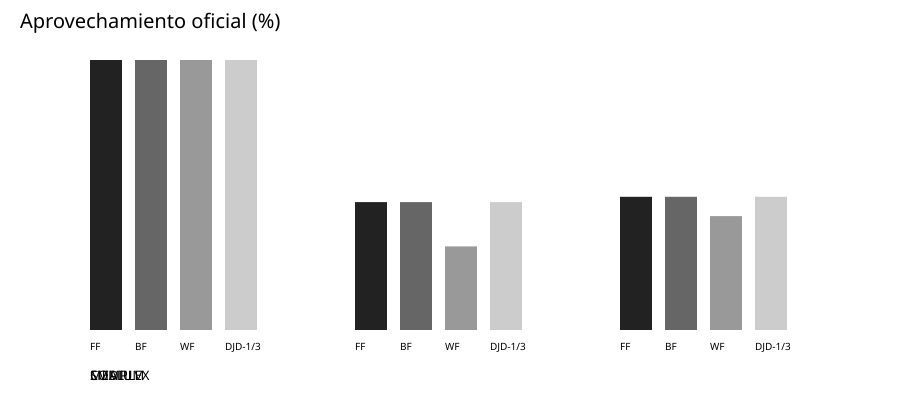

In [28]:
def svg_bars(rows, metric, title):  # Define un gráfico vectorial sencillo sin dependencias de plotting.
    cases = list(CASES)  # Fijamos únicamente los IDs oficiales de TA-027.
    methods = ["FF", "BF", "WF", "DJD-1/3"]  # Definimos orden de métodos.
    shades = ["#222222", "#666666", "#999999", "#cccccc"]  # Usamos fondo blanco y escala de grises.
    width, height = 900, 410  # Seleccionamos un tamaño de lectura para Colab.
    maximum = max(float(row[metric]) for row in rows if row["case"] in cases) or 1  # Calculamos una escala global de los fixtures.
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}">', '<rect width="100%" height="100%" fill="white"/>']  # Iniciamos un canvas blanco.
    parts.append(f'<text x="20" y="28" font-family="sans-serif" font-size="20">{title}</text>')  # Rotulamos el gráfico.
    for case_index, case in enumerate(cases):  # Recorremos cada caso oficial.
        for method_index, method in enumerate(methods):  # Recorremos los métodos en orden fijo.
            row = next(item for item in rows if item["case"] == case and item["method"] == method)  # Encontramos la métrica real.
            value = float(row[metric])  # Convertimos el campo CSV a número para escalarlo.
            bar_height = value * 270 / maximum  # Aplicamos una escala común para todas las barras.
            x = 90 + case_index * 265 + method_index * 45  # Ubicamos la barra dentro del grupo.
            parts.append(f'<rect x="{x}" y="{330-bar_height:.1f}" width="32" height="{bar_height:.1f}" fill="{shades[method_index]}"/>')  # Dibujamos la barra gris.
            parts.append(f'<text x="{x}" y="350" font-family="sans-serif" font-size="10">{method}</text>')  # Añadimos etiqueta de método.
        parts.append(f'<text x="90" y="380" font-family="sans-serif" font-size="13">{case.replace("EXP-", "").replace("-001", "")}</text>')  # Etiquetamos el fixture.
    parts.append('</svg>')  # Cerramos la imagen vectorial.
    return "".join(parts)  # Devolvemos la salida que guardará el notebook.
official_rows = [row for row in consolidated if row["case"] in CASES]  # Excluimos la demo del análisis TA-027.
utilization_chart = svg_bars(official_rows, "utilization_pct", "Aprovechamiento oficial (%)")  # Generamos comparación de utilización.
print(utilization_chart)  # El constructor guarda este texto como salida SVG renderizable.

### Interpretación de la salida

El gráfico describe las métricas obtenidas y no predice resultados de otras órdenes.

## Celda 34. Fuentes utilizadas

### Qué hace esta celda

Resume retazos y planchas consumidas en TA-027.

### Por qué la necesitamos

El uso de fuentes es un indicador operativo aparte del aprovechamiento.

### Qué deberíamos observar

Retazos y planchas se comparan con prioridad vigente preservada.

In [29]:
for row in official_rows:  # Recorremos las métricas oficiales para detallar cada tipo de fuente.
    print(row["case"], row["method"], "retazos:", row["remnants_used"], "planchas:", row["sheets_used"])  # Reportamos inventario consumido.

EXP-SMALL-001 FF retazos: 1 planchas: 1
EXP-SMALL-001 BF retazos: 1 planchas: 1
EXP-SMALL-001 WF retazos: 1 planchas: 1
EXP-SMALL-001 DJD-1/3 retazos: 1 planchas: 1
EXP-MEDIUM-001 FF retazos: 2 planchas: 1
EXP-MEDIUM-001 BF retazos: 2 planchas: 1
EXP-MEDIUM-001 WF retazos: 2 planchas: 2
EXP-MEDIUM-001 DJD-1/3 retazos: 2 planchas: 1
EXP-COMPLEX-001 FF retazos: 3 planchas: 3
EXP-COMPLEX-001 BF retazos: 3 planchas: 3
EXP-COMPLEX-001 WF retazos: 3 planchas: 4
EXP-COMPLEX-001 DJD-1/3 retazos: 3 planchas: 3


### Interpretación de la salida

Las fuentes utilizadas se reportan por tipo y caso; la política común conserva retazo antes que plancha.

## Celda 35. Tiempo computacional

### Qué hace esta celda

Grafica el runtime local medido y muestra el número de pasos de tolerancia DJD.

### Por qué la necesitamos

La combinatoria puede elevar el costo aun cuando la solución final coincida.

### Qué deberíamos observar

Complejo contiene más candidatos y secuencias que SMALL.

In [30]:
runtime_chart = svg_bars(official_rows, "runtime_ms", "Tiempo observado por ejecución (ms)")  # Generamos las barras de tiempo con escala compartida.
print(runtime_chart)  # Embebemos el gráfico como SVG.
for case_id in CASES:  # Recorremos solamente TA-027 para leer tolerancia.
    row = next(item for item in consolidated if item["case"] == case_id and item["method"] == "DJD-1/3")  # Seleccionamos DJD.
    print(case_id, "pasos de w:", row["waste_tolerance_steps"], "tiempo ms:", row["runtime_ms"])  # Informamos costo y relajaciones.

### Interpretación de la salida

El tiempo depende de máquina y carga; combina con contadores de poda y geometría para interpretar el costo.

## Celda 36. Observaciones experimentales

### Qué hace esta celda

Resume cobertura, diferencias de grupos, costo y límites observados.

### Por qué la necesitamos

El objetivo es fundamentar GO/NO-GO sin buscar declarar un método ganador.

### Qué deberíamos observar

El caso discriminante comprueba agrupación; los tres fixtures determinan el comportamiento comparativo.

In [31]:
for case_id in (*CASES, DISCRIMINANT):  # Resumimos fixtures y el caso didáctico por separado.
    rows = [row for row in consolidated if row["case"] == case_id]  # Filtramos cuatro métodos.
    coverage = {row["placed_units"] for row in rows}  # Comprobamos si la cobertura cambia entre métodos.
    print(case_id, "cobertura igual:", len(coverage) == 1, "unidades: ", [row["placed_units"] for row in rows])  # Presentamos cobertura observada.
print("DJD seleccionó tamaños:", disc_trace["selected_combination_sizes"])  # Confirmamos que el ejemplo ejercita tamaño 2.
for case_id in ("EXP-MEDIUM-001", "EXP-COMPLEX-001"):  # Revisamos los casos donde DJD paga mayor costo.
    djd = next(row for row in consolidated if row["case"] == case_id and row["method"] == "DJD-1/3")  # Leemos DJD.
    ff = next(row for row in consolidated if row["case"] == case_id and row["method"] == "FF")  # Leemos FF de referencia.
    ratio = Decimal(djd["runtime_ms"]) / Decimal(ff["runtime_ms"])  # Calculamos el factor de runtime observado.
    print(case_id, "DJD/FF runtime:", round(ratio, 1), "x")  # Informamos el costo relativo medido.
print("Limitación: el caso discriminante es didáctico y no pertenece a TA-027.")  # Evitamos tratar la demo como un benchmark oficial.
print("La decisión GO/NO-GO se basa en comportamiento, reglas y costo de TA-027, no en una sola métrica.")  # Enmarcamos el criterio de viabilidad.

EXP-SMALL-001 cobertura igual: True unidades:  ['3', '3', '3', '3']
EXP-MEDIUM-001 cobertura igual: True unidades:  ['9', '9', '9', '9']
EXP-COMPLEX-001 cobertura igual: True unidades:  ['24', '24', '24', '24']
DJD-DISCRIMINANT-001 cobertura igual: True unidades:  ['3', '3', '3', '3']
DJD seleccionó tamaños: (1, 2)
EXP-MEDIUM-001 DJD/FF runtime: 8.8 x
EXP-COMPLEX-001 DJD/FF runtime: 50.0 x
Limitación: el caso discriminante es didáctico y no pertenece a TA-027.
La decisión GO/NO-GO se basa en comportamiento, reglas y costo de TA-027, no en una sola métrica.


### Interpretación de la salida

DJD toma decisiones de grupo distintas, pero en MEDIUM y COMPLEX no mejora las métricas finales y tarda considerablemente más que FF. El costo observado sostiene NO-GO para TA-042 con esta implementación.